## 1. The task

Every graph in FRANKENSTEIN is one molecule. The nodes are atoms and the edges are chemical bonds. The molecules come from a mutagenicity dataset, but each atom's chemical symbol was replaced by the pixel intensities of an MNIST digit image, a 780-dimensional vector. So the model cannot read the atom type directly; it has to recognise it from a noisy picture.

For a molecule $G=(V,E,X)$ we predict one label $y\in\{0,1\}$ for the whole graph, mutagenic or non-mutagenic. This is graph classification.

The model is a graph transformer, GraphGPS. We use the same split, the same training procedure and the same tuning budget as the GCN notebook, so the two models can be compared directly.

Kaggle already has PyTorch, so we only install PyTorch Geometric.

In [1]:
!pip install -q torch_geometric

## 2. Set the experiment budget

All the settings that control run time are here, with the same values as in the GCN notebook so both models get the same tuning budget.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs. Every run uses mini-batches of `batch_size` graphs.

The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`, that were never used for selection. The analyses use the first five of them, `abl_seeds`.

In [2]:
import time
t0 = time.time()
epochs, patience, batch_size = 200, 30, 64
n_trials, search_seeds = 20, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds = final_seeds[:5]

## 3. Load FRANKENSTEIN

FRANKENSTEIN is one of the TU Dortmund benchmark datasets, and PyG downloads it with `TUDataset`.

Its node features are continuous attributes, not discrete labels, and `TUDataset` drops continuous attributes unless we pass `use_node_attr=True`. Without it every node would get an empty feature vector.

The data goes to `/tmp` so that Kaggle does not copy the raw files into the notebook output. PyG warns on every max-pooling call that an optional package would make it faster; we silence just that message.

In [3]:
import torch
import warnings
from torch_geometric.datasets import TUDataset
warnings.filterwarnings('ignore', message='.*can be accelerated via')

dataset = TUDataset('/tmp/tud', 'FRANKENSTEIN', use_node_attr=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("graphs =", len(dataset), "   classes =", dataset.num_classes)
print("node features =", dataset.num_features, "   device =", device)

# figures go to results/, tables and other saved files go to intermediates/
import os
os.makedirs('results', exist_ok=True)
os.makedirs('intermediates', exist_ok=True)

Processing...


graphs = 4337    classes = 2
node features = 780    device = cuda


Done!


## 4. One molecule

A graph is stored as node features `x` of shape $|V|\times780$, an edge list `edge_index` of shape $2\times|E|$, and a label `y`.

In [4]:
g = dataset[0]
print(g)
print("first edges:", g.edge_index[:, :8].tolist())
print("label:", g.y.item())

Data(edge_index=[2, 56], x=[25, 780], y=[1])
first edges: [[0, 0, 0, 1, 1, 1, 2, 2], [1, 2, 3, 0, 4, 5, 0, 6]]
label: 1


## 5. Check the graphs and the features

As in the GCN notebook: every bond should be stored in both directions, and we look at isolated atoms and at the range of the features.

In [5]:
graphs = list(dataset)
X = torch.cat([g.x for g in graphs])
print("undirected graphs:", sum(g.is_undirected() for g in graphs), "of", len(graphs))
print("graphs with an isolated atom:", sum(g.has_isolated_nodes() for g in graphs))
print("feature range:", round(X.min().item(), 3), "to", round(X.max().item(), 3))

undirected graphs: 4337 of 4337
graphs with an isolated atom: 209
feature range: 0.0 to 1.0


The bonds are already stored in both directions and the features already lie in $[0,1]$, so neither needs any preprocessing.

## 6. Random-walk positional encodings

Attention on its own sees a set of atoms, not a graph. Positional encodings put the structure back. We use random-walk encodings (RWPE): for atom $v$,

$p_v=\big[P_{vv},\,(P^2)_{vv},\,\ldots,\,(P^k)_{vv}\big]$, with $P=D^{-1}A$,

the probability that a random walk started at $v$ is back at $v$ after $1,\ldots,k$ steps. For example, an atom in a six-membered ring can return after exactly 6 steps by going once around the ring.

This is the only preprocessing step, and it is computed once before training. We take $k=16$:

- The UPFD cascades are trees, where a walk can only return after an even number of steps, so the UPFD notebook kept only the even steps. Molecules have rings, and an odd ring such as a five-membered ring makes odd-step returns possible, so here we keep all 16 steps.
- An isolated atom has nowhere to walk, so its encoding is all zeros.

In [6]:
from torch_geometric.transforms import AddRandomWalkPE
add_pe = AddRandomWalkPE(walk_length=16, attr_name='pe')
graphs = [add_pe(g) for g in graphs]
print("positional encoding per atom:", tuple(graphs[0].pe.shape))
print("first atom of the first molecule:", graphs[0].pe[0].numpy().round(3))
print("molecules with an odd-step return, i.e. an odd ring:", sum(bool(g.pe[:, 0::2].count_nonzero()) for g in graphs), "of", len(graphs))

positional encoding per atom: (25, 16)
first atom of the first molecule: [0.    0.389 0.    0.247 0.019 0.183 0.028 0.149 0.032 0.129 0.033 0.117
 0.033 0.108 0.033 0.103]
molecules with an odd-step return, i.e. an odd ring: 1278 of 4337


## 7. Split into train, validation and test

FRANKENSTEIN has no official split. We rebuild exactly the GCN notebook's split: stratified 80/10/10 with the same fixed random state, so both models see the same graphs.

The validation split chooses hyperparameters and the stopping epoch. The test split is used only to report results.

In [7]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

y = np.array([g.y.item() for g in graphs])
train_idx, rest = train_test_split(np.arange(len(y)), train_size=0.8, stratify=y, random_state=0)
val_idx, test_idx = train_test_split(rest, train_size=0.5, stratify=y[rest], random_state=0)

train_set, val_set, test_set = [[graphs[i] for i in idx] for idx in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
for s, yy in zip(['train', 'val', 'test'], [y_train, y_val, y_test]):
    print(s, "  graphs =", len(yy), "  class 0 =", (yy == 0).sum(), "  class 1 =", (yy == 1).sum())

train   graphs = 3469   class 0 = 1549   class 1 = 1920
val   graphs = 434   class 0 = 193   class 1 = 241
test   graphs = 434   class 0 = 194   class 1 = 240


## 8. Reference points

The same two reference points as in the GCN notebook: always predicting the larger class, and a logistic regression on $\log|V|$, the number of atoms.

In [8]:
from sklearn.linear_model import LogisticRegression
logn = lambda d: np.log([[g.num_nodes] for g in d])
size_acc = LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test)
print("test accuracy, always the larger class:", round(max(np.mean(y_test == 0), np.mean(y_test == 1)), 4))
print("test accuracy from log|V| alone:      ", round(size_acc, 4))

test accuracy, always the larger class: 0.553
test accuracy from log|V| alone:       0.576


## 9. The GPS layer

A GPS layer runs a local message-passing step and a global attention step side by side on the same input $X$, and adds them.

The local step is GIN: $h_i^{M}=\text{MLP}\big(h_i+\sum_{j\in N(i)}h_j\big)$. It only sees the bonds.

The global step is multi-head self-attention over all atoms of the molecule: $X^{T}=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right)V$ with $Q=XW_Q$, $K=XW_K$, $V=XW_V$. It ignores the bonds, so any two atoms can exchange information in one layer however far apart they are.

Each branch has a residual connection and batch norm, and the sum goes through a two-layer MLP, again with a residual:

$X' = Y + \text{MLP}(Y)$, where $Y = \text{BN}(X^{M}+X) + \text{BN}(X^{T}+X)$.

A single layer keeps the width of its input.

In [9]:
from torch_geometric.nn import GPSConv, GINConv, MLP
layer = GPSConv(16, GINConv(MLP([16, 16, 16], norm=None)), heads=4)
h = torch.randn(g.num_nodes, 16)
print("one GPS layer:", tuple(h.shape), "->", tuple(layer(h, g.edge_index).shape))

one GPS layer: (25, 16) -> (25, 16)


## 10. From atoms to one graph vector

Each atom starts from its features and its positional encoding: $h_v^{(0)}=\big[W_x x_v \,\|\, W_p\,\text{BN}(p_v)\big]$. The 16 encoding values are normalised and mapped to 8 of the `hidden` dimensions, as in the UPFD notebook.

After $L$ GPS layers a readout pools the atom embeddings into one vector per molecule, $h_G=\text{READOUT}\{h_v^{(L)}:v\in V\}$, with the mean, the max or the sum, and an MLP maps $h_G$ to two logits.

Two switches exist only for the ablations: `pe=False` drops the positional encoding, and `local=False` drops the GIN branch, leaving a plain transformer that sees the bonds only through the encoding.

In [10]:
import torch.nn.functional as F
from torch_geometric.nn import global_mean_pool, global_max_pool, global_add_pool

pools = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=2, heads=4, dropout=0.2, pool='mean', pe=True, local=True, **_):
        super().__init__()
        self.pe = pe
        self.node = torch.nn.Linear(dataset.num_features, hidden - 8 if pe else hidden)
        self.pe_norm, self.pe_lin = torch.nn.BatchNorm1d(16), torch.nn.Linear(16, 8)
        gin = lambda: GINConv(MLP([hidden, hidden, hidden], norm=None)) if local else None
        self.convs = torch.nn.ModuleList([GPSConv(hidden, gin(), heads=heads, dropout=dropout, attn_kwargs=dict(dropout=dropout))
                                          for _ in range(layers)])
        self.pool = pools[pool]
        self.head = MLP([hidden, hidden, 2], dropout=dropout, norm=None)

    def embed(self, x, edge_index, pe, batch):
        h = self.node(x)
        if self.pe:
            h = torch.cat([h, self.pe_lin(self.pe_norm(pe))], dim=1)
        for conv in self.convs:
            h = conv(h, edge_index, batch)
        return self.pool(h, batch)

    def forward(self, x, edge_index, pe, batch):
        return self.head(self.embed(x, edge_index, pe, batch))

## 11. Train with early stopping on validation accuracy

Exactly as in the GCN notebook: cross-entropy with Adam on mini-batches of training graphs, validation accuracy after every epoch, the best weights kept, and a stop once it has not improved for `patience` epochs. The test split is never used here. The only difference is that the model also receives the positional encodings `pe`.

In [11]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=512):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

@torch.no_grad()
def predict(model, bs):
    model.eval()
    return torch.cat([model(b.x, b.edge_index, b.pe, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    best, wait = -1, 0
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.pe, b.batch), b.y).backward()
            opt.step()
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

val_b, test_b = batches(val_set), batches(test_set)

## 12. A plain GPS baseline

Before tuning anything we train a common GraphGPS starting point, the same one as in the UPFD notebook: two layers of width 64 with 4 attention heads, dropout $0.2$, mean readout, and Adam with learning rate $10^{-3}$ and weight decay $10^{-5}$.

It is trained on the ten final seeds and we report test metrics as mean and standard deviation.

In [12]:
baseline = dict(hidden=64, layers=2, heads=4, dropout=0.2, pool='mean', lr=1e-3, wd=1e-5)
base = pd.DataFrame([scores(y_test, predict(fit(baseline, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.7311  0.7276  0.7916
std   0.0132  0.0137  0.0126


## 13. The search space

We tune seven hyperparameters. Depth, width and the number of attention heads set the capacity; dropout (applied to the attention weights as well) and weight decay regularise; the readout decides how the atom embeddings become one graph vector; the learning rate controls the optimisation. GPS layers already contain batch norm, so there is no batch-norm switch here.

The full grid is too large to run, so we draw `n_trials` configurations uniformly at random (Bergstra and Bengio, 2012).

In [13]:
import random
space = dict(hidden=[32, 64, 128, 256], layers=[1, 2, 3, 4], heads=[1, 2, 4], dropout=[0.0, 0.2, 0.5],
             pool=['mean', 'max', 'add'], lr=[3e-4, 1e-3, 3e-3], wd=[0.0, 1e-5, 1e-4, 1e-3])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")

20 of 5184 configurations


## 14. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy. Averaging over seeds matters because one validation graph moves accuracy by about $0.23\%$.

In [14]:
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.7273 ± 0.0060  (261s)  {'hidden': 256, 'layers': 4, 'heads': 1, 'dropout': 0.2, 'pool': 'add', 'lr': 0.001, 'wd': 0.001}
 1  val = 0.7043 ± 0.0125  (287s)  {'hidden': 128, 'layers': 4, 'heads': 2, 'dropout': 0.5, 'pool': 'mean', 'lr': 0.003, 'wd': 1e-05}
 2  val = 0.7097 ± 0.0033  (119s)  {'hidden': 128, 'layers': 2, 'heads': 1, 'dropout': 0.5, 'pool': 'max', 'lr': 0.003, 'wd': 1e-05}
 3  val = 0.7051 ± 0.0038  (80s)  {'hidden': 128, 'layers': 1, 'heads': 4, 'dropout': 0.0, 'pool': 'add', 'lr': 0.001, 'wd': 0.001}
 4  val = 0.7442 ± 0.0164  (155s)  {'hidden': 32, 'layers': 3, 'heads': 2, 'dropout': 0.2, 'pool': 'add', 'lr': 0.003, 'wd': 1e-05}
 5  val = 0.6636 ± 0.0114  (511s)  {'hidden': 256, 'layers': 4, 'heads': 4, 'dropout': 0.2, 'pool': 'mean', 'lr': 0.003, 'wd': 0.0}
 6  val = 0.7204 ± 0.0011  (266s)  {'hidden': 32, 'layers': 4, 'heads': 4, 'dropout': 0.5, 'pool': 'add', 'lr': 0.0003, 'wd': 0.001}
 7  val = 0.7058 ± 0.0109  (122s)  {'hidden': 128, 'layers': 2, 'heads'

## 15. The best configuration

We rank by mean validation accuracy and keep the top configuration.

Each panel below shows every trial's validation accuracy against one hyperparameter. A panel where the values separate cleanly marks a choice that matters; a flat one marks a choice that does not.

    hidden  layers  heads  dropout  pool      lr      wd     val  val_std
4       32       3      2      0.2   add  0.0030  0.0000  0.7442   0.0164
9      128       4      1      0.2   add  0.0010  0.0000  0.7396   0.0033
16      32       3      4      0.0   max  0.0030  0.0001  0.7396   0.0172
10     128       2      4      0.5   add  0.0010  0.0010  0.7320   0.0076
12      64       2      1      0.5   add  0.0010  0.0010  0.7273   0.0076
0      256       4      1      0.2   add  0.0010  0.0010  0.7273   0.0060
11      32       4      2      0.5  mean  0.0010  0.0000  0.7258   0.0050
14     256       3      4      0.0  mean  0.0030  0.0010  0.7227   0.0107
6       32       4      4      0.5   add  0.0003  0.0010  0.7204   0.0011
13      32       1      4      0.0  mean  0.0003  0.0000  0.7197   0.0029

best: {'hidden': 32, 'layers': 3, 'heads': 2, 'dropout': 0.2, 'pool': 'add', 'lr': 0.003, 'wd': 1e-05}


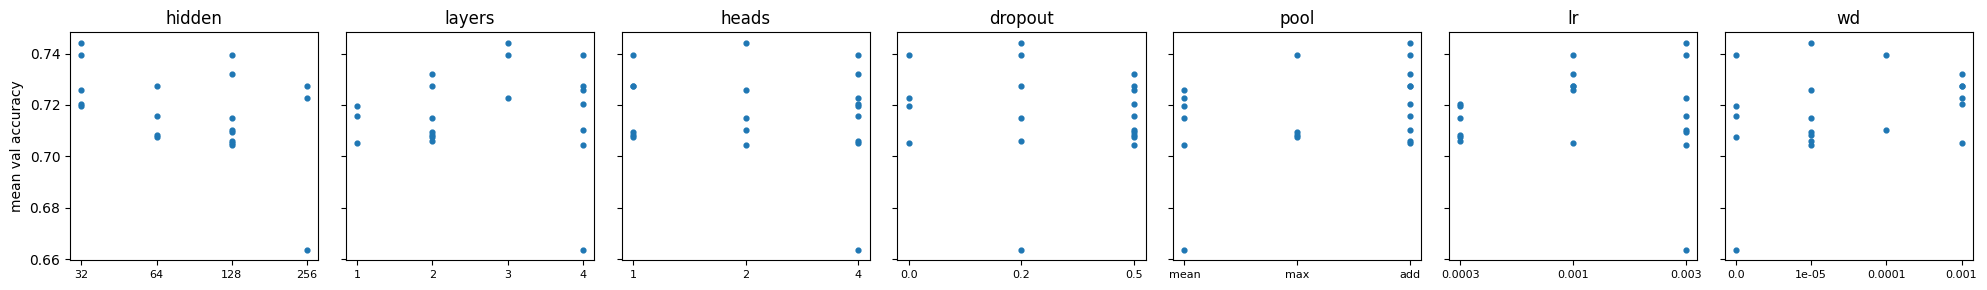

In [15]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = trials[search.index[0]]
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(20, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('results/gt_search.png', dpi=150); plt.show()

## 16. Test the tuned GPS model on ten fresh seeds

The search used other seeds. We retrain the chosen configuration on the ten final seeds and score each run once on the test graphs. The spread over seeds shows how much of any difference is noise.

In [16]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'baseline': base.mean(), 'baseline std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

     baseline  baseline std   tuned  tuned std
acc    0.7311        0.0132  0.7417     0.0180
f1     0.7276        0.0137  0.7377     0.0190
auc    0.7916        0.0126  0.8037     0.0094


## 17. The model we analyse

The analyses that need a single model use the run with the highest validation accuracy among the ten. Picking the highest test accuracy instead would be peeking at the test set.

Its confusion matrix shows whether the errors fall mostly on one class.

seed 108   val acc = 0.7581   test: {'acc': 0.7673, 'f1': 0.7654, 'auc': 0.8197}


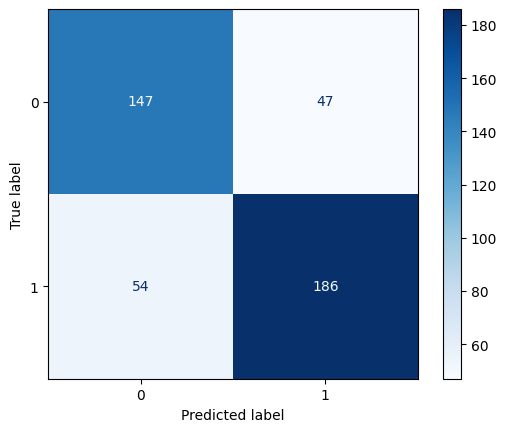

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(float(v), 4) for m, v in scores(y_test, p_best).items()})
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5)).plot(cmap='Blues')
plt.savefig('results/gt_confusion.png', dpi=150); plt.show()

## 18. Ablation: what does the model need?

An ablation removes one ingredient and retrains with the same tuned hyperparameters on the seeds in `abl_seeds`.

Two ablations change the input. Train, validation and test graphs are changed in the same way, and the positional encodings are recomputed on the changed graphs, because they are a function of the bonds.

- **No edges.** Every bond is deleted. GIN then sees only the atom itself and every encoding becomes zero, but attention still lets all atoms of a molecule talk to each other. What is left is a transformer over a bag of atoms.
- **Constant features.** Every $x_v$ becomes a vector of ones, so the model cannot tell atoms apart and only the shape of the molecule is left.

Two ablations change the model:

- **No positional encoding** (`pe=False`).
- **Attention only, no GIN** (`local=False`). The bonds then enter only through the positional encoding.

`Δ acc` is the change against the tuned model on the same seeds.

In [18]:
def no_edges(g): g.edge_index = g.edge_index[:, :0]; return g
def ones(g):     g.x = torch.ones_like(g.x); return g

def variant(f):
    return ([add_pe(f(g.clone())) for g in train_set], batches([add_pe(f(g.clone())) for g in val_set]),
            batches([add_pe(f(g.clone())) for g in test_set]))

def run(c, tr, va, te):
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in abl_seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

abl = {'tuned GPS': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges', no_edges), ('constant features', ones)]:
    abl[name] = run(best, *variant(f))
for name, change in [('no positional encoding', dict(pe=False)), ('attention only (no GIN)', dict(local=False))]:
    abl[name] = run(dict(best, **change), train_set, val_b, test_b)
print(table(abl))

                            acc      f1     auc  acc std   Δ acc
tuned GPS                0.7332  0.7295  0.8001   0.0122  0.0000
no edges                 0.5493  0.5169  0.5472   0.0171 -0.1839
constant features        0.6894  0.6804  0.7550   0.0358 -0.0438
no positional encoding   0.6668  0.6564  0.7278   0.0118 -0.0664
attention only (no GIN)  0.7000  0.6960  0.7486   0.0190 -0.0332


## 19. Depth

A GCN over-smooths as layers are added: repeated neighbourhood averaging pulls all atom embeddings of a molecule towards the same vector. Attention can also collapse to near-uniform weights, which has the same effect, so we test depth the same way as for the GCN: 1, 2, 4 and 8 layers of the tuned configuration.

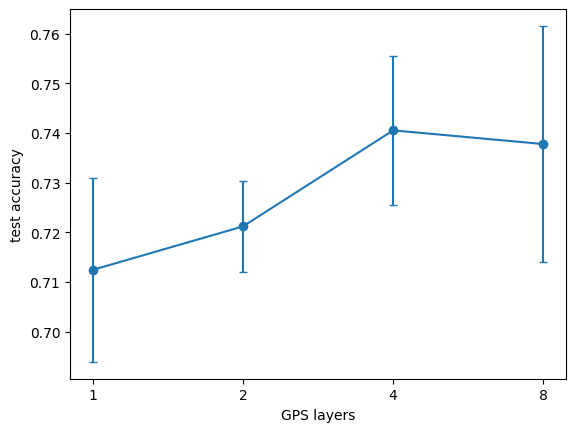

In [19]:
Ls = [1, 2, 4, 8]
depth = {L: run(dict(best, layers=L), train_set, val_b, test_b) for L in Ls}
plt.errorbar(Ls, [depth[L].acc.mean() for L in Ls], [depth[L].acc.std() for L in Ls], marker='o', capsize=3)
plt.xscale('log', base=2); plt.xticks(Ls, Ls)
plt.xlabel("GPS layers"); plt.ylabel("test accuracy")
plt.savefig('results/gt_depth.png', dpi=150); plt.show()

## 20. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per molecule. t-SNE maps these vectors to 2D while keeping near neighbours near.

On the left is the input itself, the mean of each molecule's raw atom features. On the right is the tuned GPS model's embedding. Colour is the true class, and crosses are graphs the model gets wrong.

The silhouette score, computed in the original space and not in 2D, measures class separation on a scale from $-1$ to $1$.

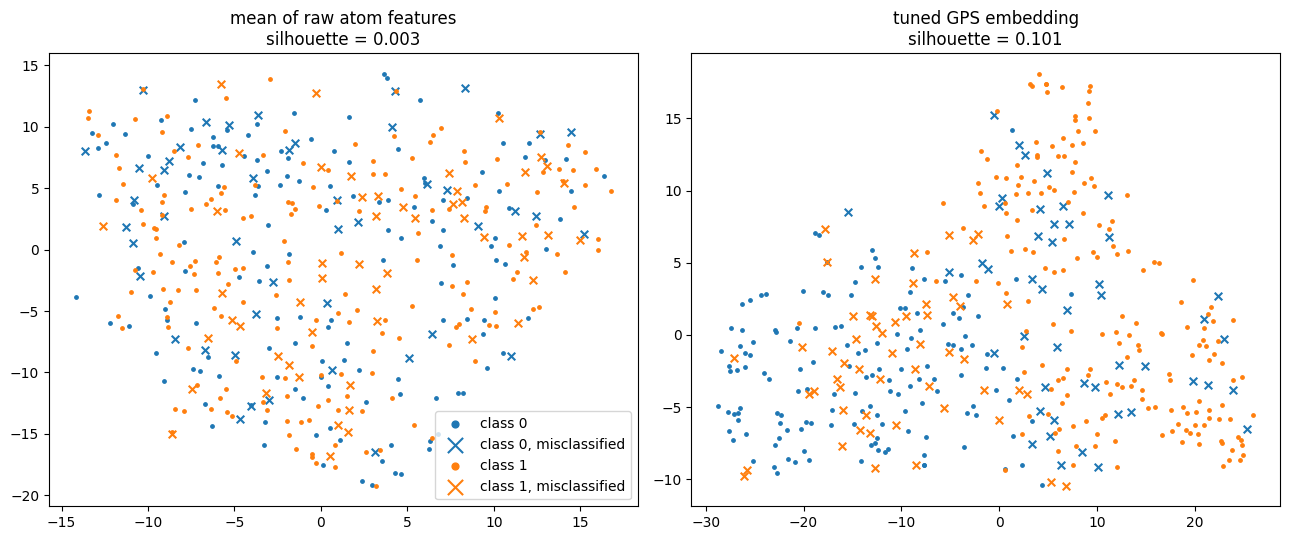

In [20]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.pe, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw atom features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GPS embedding': embed_all(model, test_b)}
sil = {name: silhouette_score(E, y_test) for name, E in Z.items()}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0).fit_transform(E)
    for c, col in [(0, 'tab:blue'), (1, 'tab:orange')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=6, c=col, label=f'class {c}')
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'class {c}, misclassified')
    a.set_title(f"{name}\nsilhouette = {sil[name]:.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('results/gt_tsne.png', dpi=150); plt.show()

## 21. Save the results

Everything needed to compare this model with the GCN goes into one JSON file, together with the split indices. The per-run test probabilities are saved too, so the models' errors can later be compared graph by graph.

In [21]:
import json
res = dict(model='GraphGPS', dataset='FRANKENSTEIN (TUDataset, 780 node attributes)',
           split=dict(rule='stratified 80/10/10, random_state=0', train=train_idx.tolist(), val=val_idx.tolist(), test=test_idx.tolist()),
           size_only_acc=size_acc, best_config=best,
           baseline=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(), tuned_runs=tuned.to_dict('list'),
           ablation=table(abl).to_dict('index'),
           depth={f'layers={L}': [v.acc.mean(), v.acc.std()] for L, v in depth.items()},
           silhouette=sil, minutes=(time.time() - t0) / 60)
json.dump(res, open('intermediates/gt_frankenstein_results.json', 'w'), indent=1, default=float)
np.save('intermediates/gt_frankenstein_test_probs.npy', P)
search.to_csv('intermediates/gt_frankenstein_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))
print(f"total run time: {res['minutes']:.0f} minutes")

saved: ablation, baseline, best_config, dataset, depth, minutes, model, silhouette, size_only_acc, split, tuned, tuned_runs
total run time: 121 minutes


## 22. Other poolings

So far we only tried the mean, the max and the sum. Here we compare them with learned poolings. The tuned model stays fixed and only the step from atom embeddings to $h_G$ changes.

| name | how it makes $h_G$ |
|---|---|
| `mean`, `max`, `add` | average, maximum or sum over the atoms |
| `att_softmax` | global attention: weighted average, the learned weights sum to 1 in each molecule |
| `att_sigmoid` | global attention: weighted sum, each atom gets its own gate between 0 and 1 |
| `sag0.5`, `sag0.8` | SAGPool: score the atoms, keep the top 50% or 80%, then sum them |
| `cls` | one extra learnable CLS token per molecule; only its final vector is read |
| `pma1`, `pma2`, `pma4` | PMA: 1, 2 or 4 learnable query vectors attend to the atoms; their outputs are concatenated |

PyG has all of them except PMA, which is a short class. `out_dim` is the length of $h_G$.

In [ ]:
from torch_geometric.nn import SAGPooling
from torch_geometric.nn.aggr import AttentionalAggregation
from torch_geometric.utils import to_dense_batch

class PMA(torch.nn.Module):
    """Pooling by Multihead Attention (Set Transformer, Lee et al., 2019)."""
    def __init__(self, dim, k, heads=4):
        super().__init__()
        self.seeds = torch.nn.Parameter(torch.randn(1, k, dim))     # k learnable queries
        self.att = torch.nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm1, self.norm2 = torch.nn.LayerNorm(dim), torch.nn.LayerNorm(dim)
        self.ff = torch.nn.Sequential(torch.nn.Linear(dim, dim), torch.nn.ReLU(), torch.nn.Linear(dim, dim))

    def forward(self, h, batch):
        atoms, mask = to_dense_batch(h, batch)                      # (graphs, max atoms, dim); mask = real atoms
        q = self.seeds.expand(len(atoms), -1, -1)                   # the same queries for every graph
        out, _ = self.att(q, atoms, atoms, key_padding_mask=~mask)  # queries attend to the real atoms only
        out = self.norm1(q + out)
        out = self.norm2(out + self.ff(out))
        return out.flatten(1)                                       # concatenate the k outputs


class Pooling(torch.nn.Module):
    """Atom embeddings -> one vector per molecule. 'cls' is handled in PoolNet below."""
    def __init__(self, name, dim):
        super().__init__()
        self.name, self.out_dim = name, dim
        if name == 'att_softmax':
            self.att = AttentionalAggregation(torch.nn.Linear(dim, 1))
        elif name == 'att_sigmoid':
            self.gate = torch.nn.Linear(dim, 1)
        elif name.startswith('sag'):
            self.sag = SAGPooling(dim, ratio=float(name[3:]))       # 'sag0.5' -> keep 50% of the atoms
        elif name.startswith('pma'):
            k = int(name[3:])                                       # 'pma4' -> 4 queries
            self.pma, self.out_dim = PMA(dim, k), k * dim

    def forward(self, h, edge_index, batch):
        if self.name in pools:                                      # mean, max, add: as before
            return pools[self.name](h, batch)
        if self.name == 'att_softmax':
            return self.att(h, batch)
        if self.name == 'att_sigmoid':
            return global_add_pool(self.gate(h).sigmoid() * h, batch)
        if self.name.startswith('sag'):
            h, _, _, batch, _, _ = self.sag(h, edge_index, batch=batch)   # keep the best atoms
            return global_add_pool(h, batch)                              # then sum them
        if self.name.startswith('pma'):
            return self.pma(h, batch)
        raise ValueError(self.name)

### The CLS token

`add_cls` adds one extra node to every molecule. The attention layers connect it to all atoms in both directions, like the CLS token of BERT or ViT. It gets no bonds, so the GIN branch does not mix it with the atoms.

In [ ]:
def add_cls(h, edge_index, batch, token, connect):
    n, n_graphs = len(h), int(batch.max()) + 1
    atom_ids = torch.arange(n, device=h.device)
    graph_ids = torch.arange(n_graphs, device=h.device)

    # 1. append one CLS node per graph: graph i gets node n + i
    h = torch.cat([h, token.expand(n_graphs, -1)])
    if connect:
        edge_index = torch.cat([edge_index, torch.stack([atom_ids, n + batch])], dim=1)   # atom -> CLS
    batch = torch.cat([batch, graph_ids])

    # 2. PyG needs the nodes of one graph next to each other, so reorder and renumber the edges
    order = batch.argsort(stable=True)
    new_id = torch.empty_like(order)
    new_id[order] = torch.arange(len(order), device=h.device)
    return h[order], new_id[edge_index], batch[order], order >= n    # last one marks the CLS nodes

### The model

`PoolNet` inherits everything from `Net` and replaces only the pooling. With `add` it is exactly the tuned model from before. `fit` builds whatever `Net` points to, so after `Net = PoolNet` the same training code is reused.

In [ ]:
class PoolNet(Net):
    """The same GPS model as before, only the pooling is replaced."""
    def __init__(self, pool, hidden, dropout, **kw):
        super().__init__(hidden=hidden, dropout=dropout, pool='add', **kw)
        self.pool = Pooling(pool, hidden)
        if self.pool.out_dim != hidden:                           # pma2 and pma4 give a longer vector
            self.head = MLP([self.pool.out_dim, hidden, 2], dropout=dropout, norm=None)
        if pool == 'cls':
            self.cls = torch.nn.Parameter(0.02 * torch.randn(1, hidden))     # added after the input encoding

    def embed(self, x, edge_index, pe, batch):
        h = torch.cat([self.node(x), self.pe_lin(self.pe_norm(pe))], dim=1)
        if self.pool.name == 'cls':
            h, edge_index, batch, is_cls = add_cls(h, edge_index, batch, self.cls, connect=False)
        for conv in self.convs:
            h = conv(h, edge_index, batch)
        if self.pool.name == 'cls':
            return h[is_cls]                                      # read only the CLS tokens
        return self.pool(h, edge_index, batch)

Net = PoolNet      # fit() now trains PoolNet

### Check before training

The output must be two logits per molecule, and putting the atoms of a molecule in another order must not change it, so `max change` should be almost 0.

In [ ]:
from torch_geometric.data import Batch

def shuffled(g):
    """The same molecule with its atoms in a random order."""
    p = torch.randperm(g.num_nodes)
    g = g.clone()
    g.edge_index = torch.argsort(p)[g.edge_index]
    g.x = g.x[p]
    g.pe = g.pe[p]
    return g

pool_names = ['mean', 'max', 'add', 'att_softmax', 'att_sigmoid', 'sag0.5', 'sag0.8', 'cls', 'pma1', 'pma2', 'pma4']
same = [Batch.from_data_list(gs).to(device) for gs in (train_set[:16], [shuffled(g) for g in train_set[:16]])]
for p in pool_names:
    net = Net(**dict(best, pool=p)).to(device).eval()
    with torch.no_grad():
        out1, out2 = [net(b.x, b.edge_index, b.pe, b.batch) for b in same]
    print(f"{p:12s} output {tuple(out1.shape)}   max change {(out1 - out2).abs().max():.1e}   parameters {sum(q.numel() for q in net.parameters())}")

mean         output (16, 2)   max change 1.3e-07   parameters 52194
max          output (16, 2)   max change 2.1e-07   parameters 52194
add          output (16, 2)   max change 3.8e-06   parameters 52194
att_softmax  output (16, 2)   max change 1.8e-07   parameters 52227
att_sigmoid  output (16, 2)   max change 1.9e-06   parameters 52227
sag0.5       output (16, 2)   max change 1.4e-06   parameters 52260
sag0.8       output (16, 2)   max change 1.2e-06   parameters 52260
cls          output (16, 2)   max change 8.9e-08   parameters 52226
pma1         output (16, 2)   max change 1.2e-07   parameters 58690
pma2         output (16, 2)   max change 1.0e-07   parameters 59746
pma4         output (16, 2)   max change 1.6e-07   parameters 61858


### Run every pooling

The tuned learning rate and dropout were chosen together with the sum, so reusing them for every pooling would favour the sum. Each pooling therefore gets the same small search:

1. **Search** 6 combinations of learning rate and dropout with `search_seeds`, and keep the one with the best mean **validation** accuracy.
2. **Test** that choice on the ten `final_seeds`.

Width, depth and weight decay stay as tuned. That is $6\times3+10=28$ training runs per pooling and $308$ in total. The table is saved after every pooling.

In [ ]:
lrs, dropouts = [3e-4, 1e-3, 3e-3], [0.0, 0.2]     # includes the tuned lr=0.003, dropout=0.2
pool_rows, pool_runs, t_pool = [], {}, time.time()

for p in pool_names:
    t = time.time()

    # 1. choose lr and dropout on the validation set
    top_val, top_c = -1, None
    for lr in lrs:
        for dropout in dropouts:
            c = dict(best, pool=p, lr=lr, dropout=dropout)
            val = np.mean([fit(c, s)[1] for s in search_seeds])
            if val > top_val:
                top_val, top_c = val, c

    # 2. test the chosen configuration on the ten final seeds
    r = pd.DataFrame([scores(y_test, predict(fit(top_c, s)[0], test_b)) for s in final_seeds])
    pool_runs[p] = r.to_dict('list')
    pool_rows.append(dict(pool=p, lr=top_c['lr'], dropout=top_c['dropout'], val=top_val, acc=r.acc.mean(), acc_std=r.acc.std(),
                          f1=r.f1.mean(), auc=r.auc.mean(), minutes=(time.time() - t) / 60))
    print(f"{p:12s} val = {top_val:.4f}   test acc = {r.acc.mean():.4f} ± {r.acc.std():.4f}   "
          f"lr = {top_c['lr']}  dropout = {top_c['dropout']}   ({pool_rows[-1]['minutes']:.0f} min)", flush=True)
    pd.DataFrame(pool_rows).to_csv('intermediates/gt_pooling_results.csv', index=False)

mean         val = 0.7504   test acc = 0.7323 ± 0.0164   lr = 0.003  dropout = 0.2   (22 min)
max          val = 0.7381   test acc = 0.7173 ± 0.0206   lr = 0.003  dropout = 0.0   (25 min)
add          val = 0.7419   test acc = 0.7171 ± 0.0269   lr = 0.003  dropout = 0.0   (23 min)
att_softmax  val = 0.7419   test acc = 0.7131 ± 0.0230   lr = 0.001  dropout = 0.0   (23 min)
att_sigmoid  val = 0.7481   test acc = 0.7350 ± 0.0192   lr = 0.003  dropout = 0.0   (23 min)
sag0.5       val = 0.7458   test acc = 0.7200 ± 0.0243   lr = 0.001  dropout = 0.2   (29 min)
sag0.8       val = 0.7350   test acc = 0.7187 ± 0.0214   lr = 0.001  dropout = 0.0   (26 min)
cls          val = 0.7419   test acc = 0.7129 ± 0.0092   lr = 0.001  dropout = 0.0   (23 min)
pma1         val = 0.7496   test acc = 0.7263 ± 0.0192   lr = 0.003  dropout = 0.0   (26 min)
pma2         val = 0.7458   test acc = 0.7228 ± 0.0145   lr = 0.001  dropout = 0.2   (26 min)
pma4         val = 0.7604   test acc = 0.7283 ± 0.0113   lr 

### Compare the poolings

The table is ranked by validation accuracy, because ranking by test accuracy would be peeking. `Δ vs add` is the change in test accuracy against the sum. `p-value` is from Welch's t-test between the ten runs of that pooling and the ten runs of the sum: above 0.05 the difference may be just seed noise. With ten comparisons, a value only just below 0.05 is weak evidence.

In [ ]:
from scipy.stats import ttest_ind
pt = pd.DataFrame(pool_rows)
pt['Δ vs add'] = pt.acc - pt.acc[pt.pool == 'add'].item()
pt['p-value'] = [ttest_ind(pool_runs[p]['acc'], pool_runs['add']['acc'], equal_var=False).pvalue for p in pt.pool]
pt = pt.sort_values('val', ascending=False)
print(pt.round(4).to_string(index=False))
print("\nbest pooling by validation accuracy:", pt.pool.iloc[0])

       pool    lr  dropout    val    acc  acc_std     f1    auc  minutes  Δ vs add  p-value
       pma4 0.003      0.0 0.7604 0.7283   0.0113 0.7247 0.7917  25.1153    0.0113   0.2440
       mean 0.003      0.2 0.7504 0.7323   0.0164 0.7287 0.7984  21.5949    0.0152   0.1477
       pma1 0.003      0.0 0.7496 0.7263   0.0192 0.7213 0.7881  25.9690    0.0092   0.3901
att_sigmoid 0.003      0.0 0.7481 0.7350   0.0192 0.7305 0.7960  22.5423    0.0180   0.1041
     sag0.5 0.001      0.2 0.7458 0.7200   0.0243 0.7133 0.7837  29.1775    0.0030   0.7968
       pma2 0.001      0.2 0.7458 0.7228   0.0145 0.7185 0.7919  25.5560    0.0058   0.5601
att_softmax 0.001      0.0 0.7419 0.7131   0.0230 0.7081 0.7765  23.1968   -0.0039   0.7303
        cls 0.001      0.0 0.7419 0.7129   0.0092 0.7088 0.7769  22.9137   -0.0041   0.6530
        add 0.003      0.0 0.7419 0.7171   0.0269 0.7115 0.7884  23.4681    0.0000   1.0000
        max 0.003      0.0 0.7381 0.7173   0.0206 0.7135 0.7795  25.0109    0.00

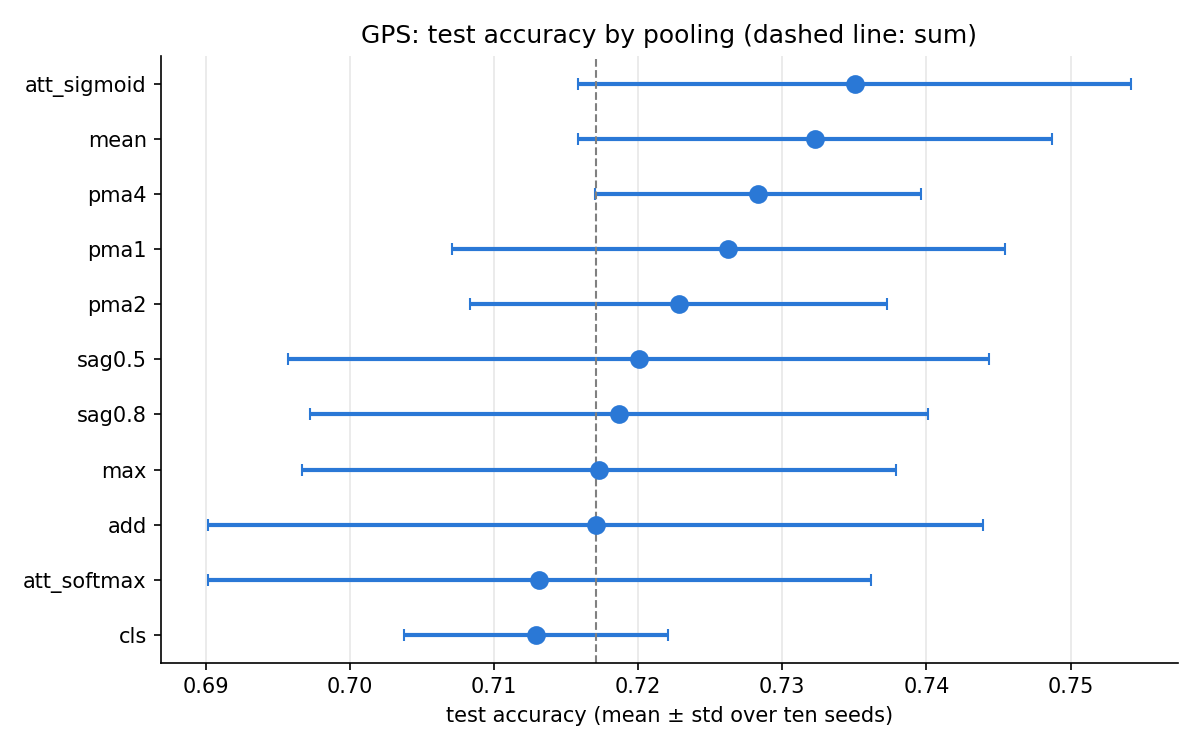

In [ ]:
import matplotlib.pyplot as plt
r = pt.sort_values('acc')
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(r.acc, r.pool, xerr=r.acc_std, fmt='o', color='#2a78d6', ms=8, lw=2, capsize=3)
ax.axvline(r.acc[r.pool == 'add'].item(), color='gray', ls='--', lw=1)      # dashed line = the sum
ax.set_xlabel("test accuracy (mean ± std over ten seeds)")
ax.set_title("GPS: test accuracy by pooling (dashed line: sum)")
ax.grid(axis='x', alpha=.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('results/gt_pooling.png', dpi=150); plt.show()

In [ ]:
import json
minutes = (time.time() - t_pool) / 60
json.dump(dict(model='GPS', tuned=best, results=pt.to_dict('records'), test_runs=pool_runs, minutes=minutes),
          open('intermediates/gt_pooling_results.json', 'w'), indent=1, default=float)
print(f"pooling section: {minutes:.0f} minutes")

pooling section: 271 minutes


## 23. Conclusion

Sections 1 to 21 ran in 121 minutes on a Kaggle T4; the pooling comparison (Section 22) took 271 more minutes in a separate run.

**Results.** Always predicting the larger class gives 0.553 test accuracy, and the number of atoms alone gives 0.576. Unlike the textbook GCN, the plain GPS baseline learns straight away: 0.731 ± 0.013 accuracy, macro-F1 0.728 ± 0.014 and ROC-AUC 0.792 ± 0.013 over ten seeds. The tuned GPS model reaches 0.742 ± 0.018 accuracy, macro-F1 0.738 ± 0.019 and ROC-AUC 0.804 ± 0.009. Tuning adds only about one point, less than one standard deviation, so the baseline was already close to the best. The chosen configuration has 3 layers of width 32, 2 attention heads, sum readout, dropout 0.2, learning rate $3\cdot10^{-3}$ and weight decay $10^{-5}$.

**Search.** Every trial learns: validation accuracy ranges from 0.664 to 0.744. The two best trials use the sum readout, as in the GCN search. The weakest trial is the largest model (width 256, 4 layers, 4 heads, mean readout). The best validation accuracy (0.744) is close to the test accuracy (0.742), so the search's choice holds up on unseen graphs.

**Errors.** The analysed run (seed 108, test accuracy 0.767) gets 186 of 240 class-1 molecules right (78%) and 147 of 194 class-0 molecules (76%). Unlike the GCN, it does not lean towards the larger class.

**What the model uses.** Over five seeds the tuned model scores 0.733. Removing the bonds lowers it by 0.184 to 0.549, below even size alone, so the model depends on the bonds more than on anything else. Constant features lower it by only 0.044 to 0.689: the shape of the molecule alone is enough to beat the full tuned GCN (0.603). Removing the random-walk encodings lowers it by 0.066 to 0.667, so knowing where the rings are helps. Keeping only attention and removing the GIN part lowers it by 0.033 to 0.700, so local message passing helps too.

**Depth.** Accuracy rises from 0.712 with 1 layer to 0.721 with 2 and 0.741 with 4, and stays at 0.738 with 8 layers. The GCN fell to 0.574 at 8 layers; the residual connections and normalisation inside each GPS layer likely keep the deep model stable. The error bars overlap, and the spread across seeds is widest at 8 layers.

**Visualisation.** The silhouette score rises from 0.003 for the raw features to 0.101 for the GPS embedding, where the GCN embedding scored 0.003. In the t-SNE plot class 0 sits mostly on the left and class 1 mostly at the top and lower right, and most misclassified molecules lie in the mixed region between them.

**Other poolings.** Section 22 searches the learning rate and dropout again for every readout and compares ten seeds each. No readout beats the sum significantly: all eleven lie between 0.713 and 0.735, with differences of at most 0.018 and $p\ge0.10$. The readouts that suit a transformer, PMA (0.723 to 0.728) and the CLS token (0.713), give no gain, and SAGPool (0.719 to 0.720) does not either. Sigmoid attention (0.735) and mean (0.732) are highest but within noise. One caveat: the sum readout scores 0.717 here, lower than the 0.742 of the main results, although the width, depth and heads are the same. Only the learning rate and dropout were searched again, and the validation set chose dropout 0 instead of 0.2. So the choice of hyperparameters on 434 validation graphs moves the test accuracy by about two points, more than any pooling difference. The sum readout and the 0.742 above stay as the results.

**GCN vs Graph Transformer.**

| | GCN (tuned) | GPS (tuned) |
|---|---|---|
| test accuracy | 0.603 ± 0.014 | 0.742 ± 0.018 |
| macro-F1 | 0.590 ± 0.022 | 0.738 ± 0.019 |
| ROC-AUC | 0.633 ± 0.011 | 0.804 ± 0.009 |
| accuracy lost without bonds | 0.016 | 0.184 |
| accuracy lost with constant features | 0.039 | 0.044 |
| accuracy with 8 layers | 0.574 | 0.738 |
| silhouette of the embedding | 0.003 | 0.101 |
| run time on a T4 | 52 min | 121 min |

The GPS model is 14 points more accurate. The ablations suggest why: the GCN barely uses the bonds, while the GPS model is built on them, through GIN's sum over neighbours and the random-walk encodings that reveal rings. Mutagenicity depends on such substructures, so a model that can read them does much better.